In [37]:
import scanpy as sc
import pandas as pd
import numpy as np

immune = sc.read_h5ad("immune.h5ad", backed="r")

print(immune.shape)
print(immune.obs["cell_type_high_resolution"].value_counts())

microglia = immune[immune.obs["cell_type_high_resolution"] == "Mic P2RY12"].to_memory()

print("Microglia cells:", microglia.n_obs)
print("Genes:", microglia.n_vars)
print("Donors:", microglia.obs["projid"].nunique())

(83889, 33538)
cell_type_high_resolution
Mic P2RY12    73061
Mic TPT1       5261
T cells        2534
CAMs           2167
Mic MKI67       866
Name: count, dtype: int64
Microglia cells: 73061
Genes: 33538
Donors: 425


In [38]:
import pandas as pd

obs = immune.obs

summary = pd.DataFrame({
    "Column": obs.columns,
    "Dtype": [str(obs[c].dtype) for c in obs.columns],
    "Unique values": [obs[c].nunique() for c in obs.columns],
    "Missing": [obs[c].isna().sum() for c in obs.columns],
    "Examples": [obs[c].dropna().astype(str).unique()[:5].tolist() for c in obs.columns]
})

display(summary)

print("\nAll columns:")
print(obs.columns.tolist())

print("\nFirst 10 rows:")
display(obs.head(10))

,Column,Dtype,Unique values,Missing,Examples
0,projid,int32,426,0,"[11409232, 11336574, 10260309, 10248033, 20207..."
1,cell_type_high_resolution,object,5,0,"[Mic P2RY12, T cells, CAMs, Mic TPT1, Mic MKI67]"
2,cell_barcode,object,83889,0,"[AACTTTCAGGATGGTC-1-0, ACGGGCTCAATCAGAA-1-0, A..."
3,msex,int32,3,0,"[1, 0, -2147483648]"
4,age_death,float64,372,7598,"[80.09856263, 89.02669405, 88.39972621, 88.468..."
5,gpath,float64,354,7598,"[0.040827993, 1.655030021, 0.053074859, 0.9914..."
6,amyloid,float64,303,7598,"[0.0, 2.1241417206318958, 1.5126516437464086, ..."
7,tangles,float64,375,7598,"[0.7465783443253697, 3.158633231219712, 0.4587..."
8,cogn_decline,float64,373,7598,"[0.341848172, 3.79209985, -0.175472764, 2.4273..."
9,AD_status,float64,61594,22282,"[-0.052006581809525866, -0.20717256802745476, ..."



All columns:
['projid', 'cell_type_high_resolution', 'cell_barcode', 'msex', 'age_death', 'gpath', 'amyloid', 'tangles', 'cogn_decline', 'AD_status']

First 10 rows:


,projid,cell_type_high_resolution,cell_barcode,msex,age_death,gpath,amyloid,tangles,cogn_decline,AD_status
AACTTTCAGGATGGTC-1-0,11409232,Mic P2RY12,AACTTTCAGGATGGTC-1-0,1,80.098563,0.040828,0.0,0.746578,0.341848,-0.052007
ACGGGCTCAATCAGAA-1-0,11409232,Mic P2RY12,ACGGGCTCAATCAGAA-1-0,1,80.098563,0.040828,0.0,0.746578,0.341848,-0.207173
ACTTACTGTGAAATCA-1-0,11409232,T cells,ACTTACTGTGAAATCA-1-0,1,80.098563,0.040828,0.0,0.746578,0.341848,NaN
AGCGGTCAGATGTTAG-1-0,11409232,Mic P2RY12,AGCGGTCAGATGTTAG-1-0,1,80.098563,0.040828,0.0,0.746578,0.341848,-0.157237
AGTGAGGGTGGTAACG-1-0,11409232,Mic P2RY12,AGTGAGGGTGGTAACG-1-0,1,80.098563,0.040828,0.0,0.746578,0.341848,0.315541
ATTACTCAGGAGTAGA-1-0,11409232,Mic P2RY12,ATTACTCAGGAGTAGA-1-0,1,80.098563,0.040828,0.0,0.746578,0.341848,0.286121
CAACCAACAAGCGTAG-1-0,11409232,Mic P2RY12,CAACCAACAAGCGTAG-1-0,1,80.098563,0.040828,0.0,0.746578,0.341848,-0.649683
CAGGTGCAGTCCATAC-1-0,11409232,Mic P2RY12,CAGGTGCAGTCCATAC-1-0,1,80.098563,0.040828,0.0,0.746578,0.341848,0.019239
CGATGGCGTCTTGTCC-1-0,11409232,Mic P2RY12,CGATGGCGTCTTGTCC-1-0,1,80.098563,0.040828,0.0,0.746578,0.341848,-0.454261
CGATGGCGTTCTGTTT-1-0,11409232,Mic P2RY12,CGATGGCGTTCTGTTT-1-0,1,80.098563,0.040828,0.0,0.746578,0.341848,0.396321


In [39]:
cols = ["age_death", "gpath", "amyloid", "tangles", "cogn_decline", "AD_status"]

missing = immune.obs.groupby("cell_type_high_resolution", observed=True)[cols].agg(
    lambda x: x.isna().mean() * 100
)

print("Percentage missing by cell type:")
display(missing.round(2))

Percentage missing by cell type:


,age_death,gpath,amyloid,tangles,cogn_decline,AD_status
cell_type_high_resolution,,,,,,
CAMs,8.91,8.91,8.91,8.91,8.91,30.41
Mic MKI67,10.39,10.39,10.39,10.39,10.39,24.60
Mic P2RY12,8.96,8.96,8.96,8.96,8.96,24.86
Mic TPT1,9.41,9.41,9.41,9.41,9.41,27.50
T cells,10.81,10.81,10.81,10.81,10.81,71.03


In [40]:
micro_obs = immune.obs[
    immune.obs["cell_type_high_resolution"] == "Mic P2RY12"
]

print("Microglia cells:", len(micro_obs))
print("Microglia donors:", micro_obs["projid"].nunique())

print("\nMissing values:")
display(micro_obs[cols].isna().sum())

print("\nMissing percentages:")
display((micro_obs[cols].isna().mean() * 100).round(2))

Microglia cells: 73061
Microglia donors: 425

Missing values:


age_death        6546
gpath            6546
amyloid          6546
tangles          6546
cogn_decline     6546
AD_status       18163
dtype: int64


Missing percentages:


age_death        8.96
gpath            8.96
amyloid          8.96
tangles          8.96
cogn_decline     8.96
AD_status       24.86
dtype: float64

In [41]:
import scanpy as sc
import pandas as pd
import numpy as np

immune = sc.read_h5ad("immune.h5ad", backed="r")

adata = immune[
    immune.obs["cell_type_high_resolution"] == "Mic P2RY12"
].to_memory()

print("Microglia cells:", adata.n_obs)
print("Genes:", adata.n_vars)
print("Donors:", adata.obs["projid"].nunique())
print("Unique barcodes:", adata.obs_names.is_unique)

display(adata.obs.head())

Microglia cells: 73061
Genes: 33538
Donors: 425
Unique barcodes: True


,projid,cell_type_high_resolution,cell_barcode,msex,age_death,gpath,amyloid,tangles,cogn_decline,AD_status
AACTTTCAGGATGGTC-1-0,11409232,Mic P2RY12,AACTTTCAGGATGGTC-1-0,1,80.098563,0.040828,0.0,0.746578,0.341848,-0.052007
ACGGGCTCAATCAGAA-1-0,11409232,Mic P2RY12,ACGGGCTCAATCAGAA-1-0,1,80.098563,0.040828,0.0,0.746578,0.341848,-0.207173
AGCGGTCAGATGTTAG-1-0,11409232,Mic P2RY12,AGCGGTCAGATGTTAG-1-0,1,80.098563,0.040828,0.0,0.746578,0.341848,-0.157237
AGTGAGGGTGGTAACG-1-0,11409232,Mic P2RY12,AGTGAGGGTGGTAACG-1-0,1,80.098563,0.040828,0.0,0.746578,0.341848,0.315541
ATTACTCAGGAGTAGA-1-0,11409232,Mic P2RY12,ATTACTCAGGAGTAGA-1-0,1,80.098563,0.040828,0.0,0.746578,0.341848,0.286121


In [42]:
%load_ext rpy2.ipython

In [43]:
%%R
library(Seurat)

immune <- readRDS("Immune_cells.rds")

microglia <- subset(
    immune,
    subset = cell_type_high_resolution == "Mic P2RY12"
)

cat("Microglia cells:", ncol(microglia), "\n")
cat("Donors:", length(unique(microglia$subject)), "\n")

R[write to console]: Loading required package: SeuratObject

R[write to console]: Loading required package: sp

R[write to console]: ‘SeuratObject’ was built with package ‘Matrix’ 1.7.5 but the current
version is 1.7.6; it is recomended that you reinstall ‘SeuratObject’ as
the ABI for ‘Matrix’ may have changed

R[write to console]: 
Attaching package: ‘SeuratObject’


R[write to console]: The following objects are masked from ‘package:base’:

    intersect, t





    an issue that caused a segfault when used with rpy2:
    https://github.com/rstudio/reticulate/pull/1188
    Make sure that you use a version of that package that includes
    the fix.
    Microglia cells: 73061 
Donors: 425 


In [44]:
import rpy2.robjects as ro
from rpy2.robjects import pandas2ri
from rpy2.robjects.conversion import localconverter
import pandas as pd
import numpy as np

r_meta = ro.r("as.data.frame(microglia@meta.data)")

with localconverter(ro.default_converter + pandas2ri.converter):
    micro_meta = ro.conversion.rpy2py(r_meta)

micro_meta.index = micro_meta.index.astype(str)

print("Shape:", micro_meta.shape)
print("Columns:", micro_meta.columns.tolist())
display(micro_meta.head())

Shape: (73061, 2)
Columns: ['cell_type_high_resolution', 'subject']


,cell_type_high_resolution,subject
AACTTTCAGGATGGTC-1-0,Mic P2RY12,ROSMAP-52226
ACGGGCTCAATCAGAA-1-0,Mic P2RY12,ROSMAP-52226
AGCGGTCAGATGTTAG-1-0,Mic P2RY12,ROSMAP-52226
AGTGAGGGTGGTAACG-1-0,Mic P2RY12,ROSMAP-52226
ATTACTCAGGAGTAGA-1-0,Mic P2RY12,ROSMAP-52226


In [45]:
diagnosis = pd.read_csv("individual_metadata_deidentified.tsv", sep="\t")

diagnosis["subject"] = diagnosis["subject"].astype(str).str.strip()

assert diagnosis["subject"].is_unique
assert micro_meta.index.is_unique
assert adata.obs_names.isin(micro_meta.index).all()

original = micro_meta.reindex(adata.obs_names)

binary_status = (
    original["subject"]
    .map(diagnosis.set_index("subject")["Pathologic_diagnosis_of_AD"])
    .astype("string")
    .str.strip()
    .str.lower()
    .map({"yes": 1, "no": 0})
)

print("Missing binary labels:", binary_status.isna().sum())
print(binary_status.value_counts(dropna=False))

assert binary_status.notna().all()

adata.obs["AD_status_continuous_original"] = adata.obs["AD_status"].copy()
adata.obs["AD_status"] = binary_status.to_numpy().astype(int)

print("\nBinary AD status:")
print(adata.obs["AD_status"].value_counts())

Missing binary labels: 0
subject
1    40415
0    32646
Name: count, dtype: int64

Binary AD status:
AD_status
1    40415
0    32646
Name: count, dtype: int64


In [46]:
meta = pd.read_csv("Metadata.csv")

print("APOE columns:", [c for c in meta.columns if "apoe" in c.lower()])

assert "projid" in meta.columns
assert "apoe_genotype" in meta.columns

meta["projid"] = meta["projid"].astype(str).str.strip()
adata.obs["projid"] = adata.obs["projid"].astype(str).str.strip()

apoe = meta[["projid", "apoe_genotype"]].drop_duplicates()

assert apoe["projid"].is_unique

adata.obs["apoe_genotype"] = adata.obs["projid"].map(
    apoe.set_index("projid")["apoe_genotype"]
)

print("Missing APOE:", adata.obs["apoe_genotype"].isna().sum())
print(adata.obs["apoe_genotype"].value_counts(dropna=False))

APOE columns: ['apoe_genotype']
Missing APOE: 44
apoe_genotype
33.0    44768
34.0    18093
23.0     7005
24.0     1651
44.0     1235
22.0      265
NaN        44
Name: count, dtype: int64


In [53]:

print("Available columns:")
print(adata.obs.columns.tolist())

print("\nAge-related columns:")
print([c for c in adata.obs.columns if "age" in c.lower()])

print("\nOriginal age values:")
print(original["age_death"].value_counts(dropna=False).head(20))


Available columns:
['projid', 'cell_type_high_resolution', 'cell_barcode', 'msex', 'age_death', 'gpath', 'amyloid', 'tangles', 'cogn_decline', 'AD_status', 'AD_status_continuous_original', 'apoe_genotype', 'subject']

Age-related columns:
['age_death']

Original age values:
age_death
90+        155
(85,90]    139
(80,85]     84
(75,80]     35
(70,75]     14
Name: count, dtype: int64


In [49]:
import pandas as pd

original = pd.read_csv("individual_metadata_deidentified.tsv", sep="\t")

print(original.columns.tolist())
display(original.head())

['subject', 'msex', 'age_death', 'pmi', 'race', 'Pathologic_diagnosis_of_AD']


,subject,msex,age_death,pmi,race,Pathologic_diagnosis_of_AD
0,ROSMAP-10132,0,90+,7.0,1,yes
1,ROSMAP-10643,0,90+,13.0,1,yes
2,ROSMAP-10859,1,"(80,85]",14.0,2,yes
3,ROSMAP-12078,1,"(85,90]",3.0,1,yes
4,ROSMAP-12256,1,"(85,90]",4.0,1,yes


In [54]:
import rpy2.robjects as ro
from rpy2.robjects import pandas2ri
from rpy2.robjects.conversion import localconverter

r_meta = ro.r("as.data.frame(microglia@meta.data)")

with localconverter(ro.default_converter + pandas2ri.converter):
    original_meta = ro.conversion.rpy2py(r_meta)

original_meta.index = original_meta.index.astype(str)

assert original_meta.index.is_unique
assert adata.obs_names.isin(original_meta.index).all()

adata.obs["subject"] = original_meta["subject"].reindex(adata.obs_names).to_numpy()

print("Missing subjects:", adata.obs["subject"].isna().sum())
print("Unique subjects:", adata.obs["subject"].nunique())
print("Unique projids:", adata.obs["projid"].nunique())

print("\nProjids per subject:")
print(adata.obs.groupby("subject")["projid"].nunique().value_counts())

print("\nSubjects per projid:")
print(adata.obs.groupby("projid")["subject"].nunique().value_counts())


Missing subjects: 0
Unique subjects: 425
Unique projids: 425

Projids per subject:
projid
1    425
Name: count, dtype: int64

Subjects per projid:
subject
1    425
Name: count, dtype: int64


In [55]:

import scanpy as sc
import pandas as pd
import numpy as np

ad_diff = sc.read_h5ad("Microglia_AD_diffusion_CPP_scored.h5ad")
sn_labels = pd.read_csv("microglia_SN_labels.csv")

sn_labels["cell"] = sn_labels["cell"].astype(str)
sn_labels = sn_labels.set_index("cell")

assert ad_diff.obs_names.is_unique
assert sn_labels.index.is_unique

ad_diff.obs["SN"] = sn_labels["SN"].reindex(ad_diff.obs_names)

print("Total cells:", ad_diff.n_obs)
print("Cells with CPP scores:", ad_diff.obs["AD_score_diffusion_CPP"].notna().sum())
print("Cells with SN labels:", ad_diff.obs["SN"].notna().sum())
print("\nSN distribution:")
print(ad_diff.obs["SN"].value_counts(dropna=False))


Total cells: 72994
Cells with CPP scores: 71205
Cells with SN labels: 71205

SN distribution:
SN
SN1    37938
SN2    24002
SN3     9265
NaN     1789
Name: count, dtype: int64


In [56]:

import scanpy as sc
import pandas as pd

original = sc.read_h5ad("Microglia_preprocessed_PCA50.h5ad")

print("Original columns:", original.obs.columns.tolist())
print("Current columns:", ad_diff.obs.columns.tolist())
print("Same cells:", ad_diff.obs_names.isin(original.obs_names).sum())

Original columns: ['cell_type_high_resolution', 'subject']
Current columns: ['cell_type_high_resolution', 'subject', 'msex', 'age_death', 'pmi', 'race', 'Pathologic_diagnosis_of_AD', 'AD_status', 'Age', 'Sex_numeric', 'PMI', 'AD_score', 'AD_score_diffusion_CPP', 'SN']
Same cells: 72994


In [57]:

import scanpy as sc
import pandas as pd

immune = sc.read_h5ad("immune.h5ad", backed="r")

print("Immune cells:", immune.n_obs)
print("Columns:", immune.obs.columns.tolist())

shared = ad_diff.obs_names.intersection(immune.obs_names)

print("Shared cell barcodes:", len(shared))
print("Diffusion cells:", ad_diff.n_obs)

assert "projid" in immune.obs.columns
assert len(shared) == ad_diff.n_obs

projid_map = immune.obs.loc[ad_diff.obs_names, "projid"]

ad_diff.obs["projid"] = projid_map.astype(str).to_numpy()

print("Missing projid:", ad_diff.obs["projid"].isna().sum())
print("Unique projids:", ad_diff.obs["projid"].nunique())


Immune cells: 83889
Columns: ['projid', 'cell_type_high_resolution', 'cell_barcode', 'msex', 'age_death', 'gpath', 'amyloid', 'tangles', 'cogn_decline', 'AD_status']
Shared cell barcodes: 72994
Diffusion cells: 72994
Missing projid: 0
Unique projids: 424


In [58]:

import pandas as pd
import numpy as np

amyloid_meta = meta[["projid", "amyloid", "apoe_genotype"]].copy()

amyloid_meta["projid"] = amyloid_meta["projid"].astype(str).str.strip()
amyloid_meta["amyloid"] = pd.to_numeric(amyloid_meta["amyloid"], errors="coerce")

assert amyloid_meta["projid"].is_unique

lookup = amyloid_meta.set_index("projid")

ad_diff.obs["amyloid"] = ad_diff.obs["projid"].astype(str).map(lookup["amyloid"]).to_numpy()
ad_diff.obs["apoe_genotype"] = ad_diff.obs["projid"].astype(str).map(lookup["apoe_genotype"]).to_numpy()

print("Total cells:", ad_diff.n_obs)
print("Cells with amyloid:", ad_diff.obs["amyloid"].notna().sum())
print("Donors with amyloid:", ad_diff.obs.loc[ad_diff.obs["amyloid"].notna(), "projid"].nunique())
print("Cells with amyloid and SN:", ad_diff.obs[["amyloid", "SN"]].notna().all(axis=1).sum())

display(ad_diff.obs[["projid", "amyloid", "apoe_genotype", "SN", "AD_score_diffusion_CPP"]].head())

Total cells: 72994
Cells with amyloid: 72983
Donors with amyloid: 423
Cells with amyloid and SN: 71194


,projid,amyloid,apoe_genotype,SN,AD_score_diffusion_CPP
AACTTTCAGGATGGTC-1-0,11409232,0.0,33.0,SN2,-0.279968
ACGGGCTCAATCAGAA-1-0,11409232,0.0,33.0,SN1,0.279611
AGCGGTCAGATGTTAG-1-0,11409232,0.0,33.0,SN2,-0.125046
AGTGAGGGTGGTAACG-1-0,11409232,0.0,33.0,SN2,-0.059390
ATTACTCAGGAGTAGA-1-0,11409232,0.0,33.0,SN2,-0.012446


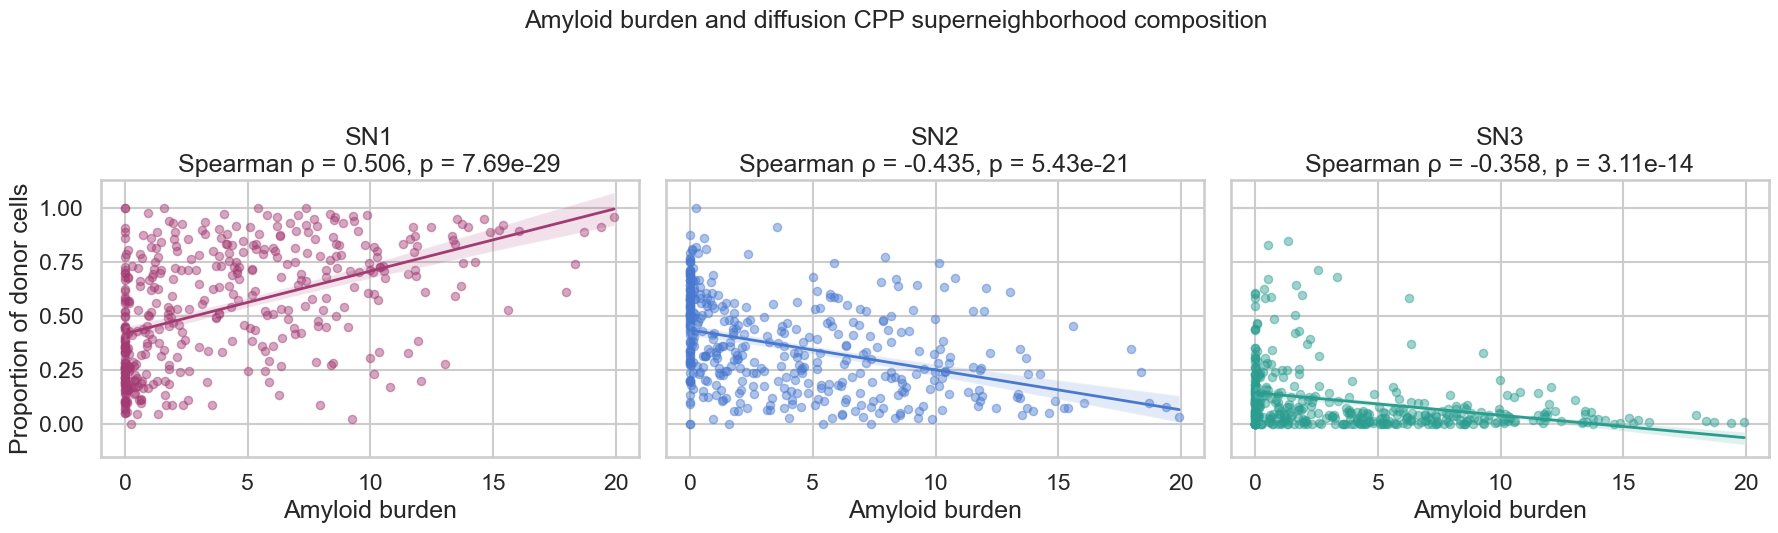

Donors analyzed: 423


,SN1_proportion,SN2_proportion,SN3_proportion,amyloid
projid,,,,
10100574,0.324324,0.574324,0.101351,0.794375
10100862,0.200565,0.548023,0.251412,1.291250
10101291,0.571429,0.428571,0.000000,0.000000
10101327,0.733333,0.266667,0.000000,3.700833
10101589,0.683673,0.306122,0.010204,1.115625


In [59]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

df = ad_diff.obs[["projid", "amyloid", "SN"]].copy()
df = df.dropna(subset=["projid", "amyloid", "SN"])
df = df[df["SN"].isin(["SN1", "SN2", "SN3"])]

counts = pd.crosstab(df["projid"], df["SN"])
counts = counts.reindex(columns=["SN1", "SN2", "SN3"], fill_value=0)

proportions = counts.div(counts.sum(axis=1), axis=0)
proportions = proportions.rename(columns=lambda x: x + "_proportion")

donor_amyloid = df.groupby("projid")["amyloid"].first()
donor_df = proportions.join(donor_amyloid)

sns.set_theme(style="whitegrid", context="talk")

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

colors = ["#A23B72", "#4878CF", "#2A9D8F"]

for ax, sn, color in zip(axes, ["SN1", "SN2", "SN3"], colors):
    y = donor_df[f"{sn}_proportion"]
    x = donor_df["amyloid"]

    rho, p = spearmanr(x, y)

    sns.regplot(
        x=x, y=y, ax=ax,
        color=color,
        scatter_kws={"alpha": 0.45, "s": 35},
        line_kws={"linewidth": 2},
        ci=95
    )

    ax.set_title(f"{sn}\nSpearman ρ = {rho:.3f}, p = {p:.2e}")
    ax.set_xlabel("Amyloid burden")
    ax.set_ylabel("Proportion of donor cells" if sn == "SN1" else "")

plt.suptitle("Amyloid burden and diffusion CPP superneighborhood composition", fontsize=18, y=1.08)
plt.tight_layout()
plt.show()

print("Donors analyzed:", len(donor_df))
display(donor_df.head())


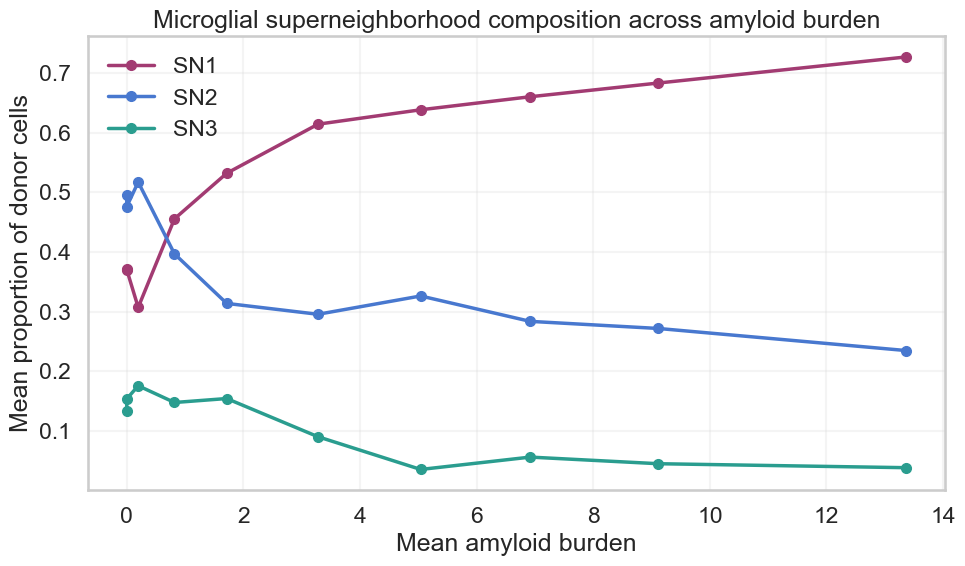

In [60]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plot_df = donor_df.copy()
plot_df["amyloid_bin"] = pd.qcut(plot_df["amyloid"].rank(method="first"), q=10, labels=False) + 1

summary = plot_df.groupby("amyloid_bin")[["SN1_proportion", "SN2_proportion", "SN3_proportion", "amyloid"]].mean()

fig, ax = plt.subplots(figsize=(10, 6))

colors = ["#A23B72", "#4878CF", "#2A9D8F"]

for sn, color in zip(["SN1", "SN2", "SN3"], colors):
    ax.plot(summary["amyloid"], summary[f"{sn}_proportion"], marker="o", markersize=7, linewidth=2.5, color=color, label=sn)

ax.set_xlabel("Mean amyloid burden")
ax.set_ylabel("Mean proportion of donor cells")
ax.set_title("Microglial superneighborhood composition across amyloid burden")
ax.legend(frameon=False)
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


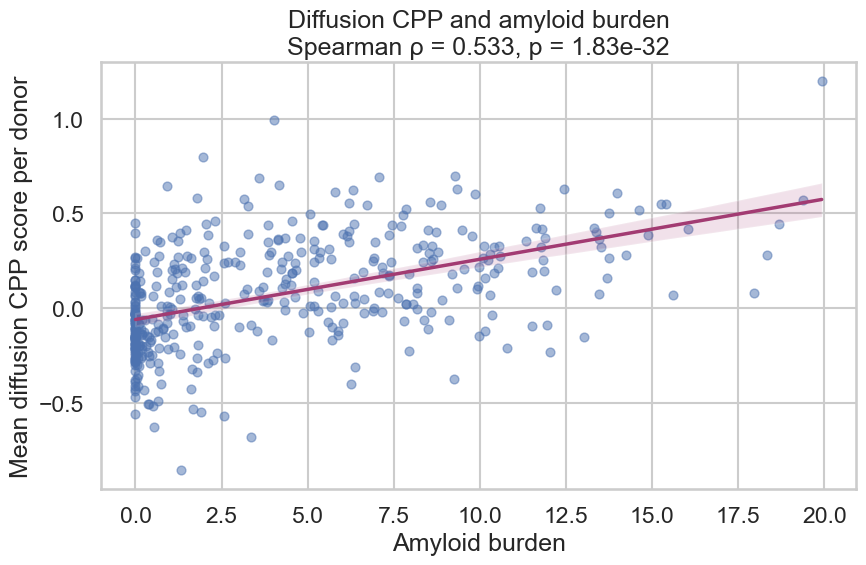

Donors: 423
Spearman rho: 0.533325865123814
P-value: 1.834202460918765e-32


In [61]:

from scipy.stats import spearmanr
import seaborn as sns
import matplotlib.pyplot as plt

score_df = ad_diff.obs[["projid", "amyloid", "AD_score_diffusion_CPP"]].dropna().copy()

donor_scores = score_df.groupby("projid").agg(
    amyloid=("amyloid", "first"),
    mean_CPP=("AD_score_diffusion_CPP", "mean"),
    median_CPP=("AD_score_diffusion_CPP", "median"),
    n_cells=("AD_score_diffusion_CPP", "size")
).reset_index()

rho, p = spearmanr(donor_scores["amyloid"], donor_scores["mean_CPP"])

fig, ax = plt.subplots(figsize=(9, 6))

sns.regplot(
    data=donor_scores,
    x="amyloid",
    y="mean_CPP",
    scatter_kws={"alpha": 0.5, "s": 40},
    line_kws={"color": "#A23B72", "linewidth": 2.5},
    ax=ax
)

ax.set_title(f"Diffusion CPP and amyloid burden\nSpearman ρ = {rho:.3f}, p = {p:.2e}")
ax.set_xlabel("Amyloid burden")
ax.set_ylabel("Mean diffusion CPP score per donor")

plt.tight_layout()
plt.show()

print("Donors:", len(donor_scores))
print("Spearman rho:", rho)
print("P-value:", p)


In [62]:
import pandas as pd
import numpy as np

std = pd.read_csv("standardCPP_microglia_super_neighborhood_labels.csv")
std_scores = pd.read_csv("standard_CPP_scores.csv")

print("Standard SN labels:", std.shape)
print("Standard CPP scores:", std_scores.shape)

print("\nStandard SN columns:")
print(std.columns.tolist())

print("\nStandard CPP score columns:")
print(std_scores.columns.tolist())

print("\nStandard SN labels:")
display(std.head())

print("\nStandard CPP scores:")
display(std_scores.head())

print("\nDiffusion CPP columns:")
print(ad_diff.obs.columns.tolist())

Standard SN labels: (72038, 2)
Standard CPP scores: (72994, 2)

Standard SN columns:
['cell', 'SN']

Standard CPP score columns:
['cell', 'standard_cpp_score']

Standard SN labels:


,cell,SN
0,AACTTTCAGGATGGTC-1-0,SN3
1,ACGGGCTCAATCAGAA-1-0,SN3
2,AGCGGTCAGATGTTAG-1-0,SN3
3,AGTGAGGGTGGTAACG-1-0,SN1
4,ATTACTCAGGAGTAGA-1-0,SN3



Standard CPP scores:


,cell,standard_cpp_score
0,AACTTTCAGGATGGTC-1-0,-0.316273
1,ACGGGCTCAATCAGAA-1-0,-0.454329
2,AGCGGTCAGATGTTAG-1-0,-0.159507
3,AGTGAGGGTGGTAACG-1-0,0.097890
4,ATTACTCAGGAGTAGA-1-0,-0.131159



Diffusion CPP columns:
['cell_type_high_resolution', 'subject', 'msex', 'age_death', 'pmi', 'race', 'Pathologic_diagnosis_of_AD', 'AD_status', 'Age', 'Sex_numeric', 'PMI', 'AD_score', 'AD_score_diffusion_CPP', 'SN', 'projid', 'amyloid', 'apoe_genotype']


Total cells: 72994
Cells with both scores: 70286
Cells with both SN labels: 70286

Donors compared: 423
Standard CPP:  rho = 0.5649, p = 5.031e-37
Diffusion CPP: rho = 0.5339, p = 1.547e-32


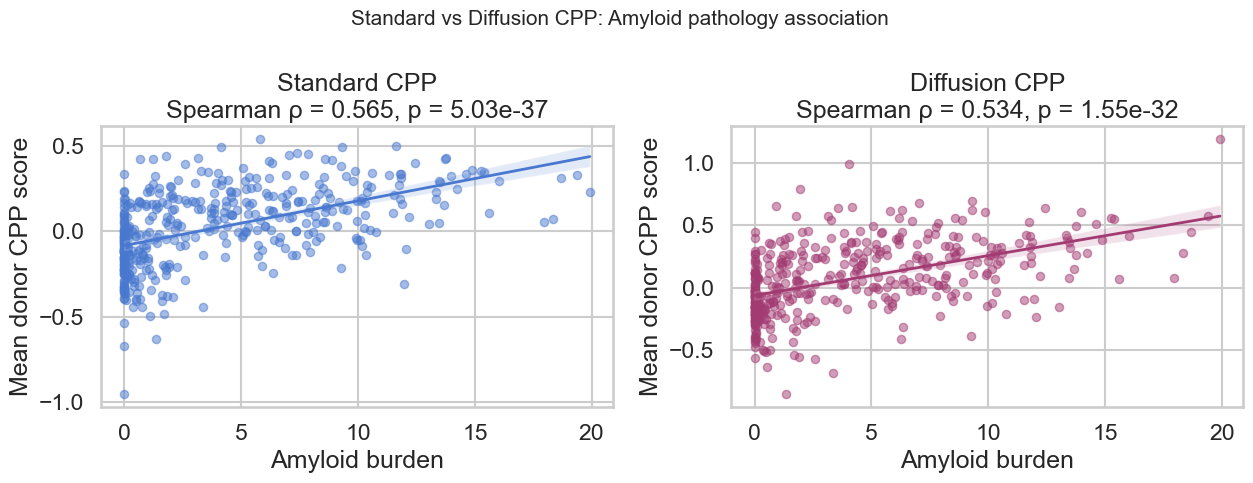

In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

standard = std_scores.set_index("cell")["standard_cpp_score"]
standard_sn = std.set_index("cell")["SN"]

compare = ad_diff.obs[
    ["projid", "amyloid", "AD_score_diffusion_CPP", "SN"]
].copy()

compare["standard_CPP"] = standard.reindex(compare.index)
compare["standard_SN"] = standard_sn.reindex(compare.index)

compare["projid"] = compare["projid"].astype(str)
compare["amyloid"] = pd.to_numeric(compare["amyloid"], errors="coerce")

print("Total cells:", len(compare))
print("Cells with both scores:", compare[["standard_CPP", "AD_score_diffusion_CPP"]].notna().all(axis=1).sum())
print("Cells with both SN labels:", compare[["SN", "standard_SN"]].notna().all(axis=1).sum())

matched = compare.dropna(subset=["standard_CPP", "AD_score_diffusion_CPP", "amyloid"]).copy()

donor_compare = matched.groupby("projid").agg(
    amyloid=("amyloid", "first"),
    standard_CPP=("standard_CPP", "mean"),
    diffusion_CPP=("AD_score_diffusion_CPP", "mean"),
    n_cells=("standard_CPP", "size")
).reset_index()

rho_std, p_std = spearmanr(donor_compare["amyloid"], donor_compare["standard_CPP"])
rho_diff, p_diff = spearmanr(donor_compare["amyloid"], donor_compare["diffusion_CPP"])

print("\nDonors compared:", len(donor_compare))
print(f"Standard CPP:  rho = {rho_std:.4f}, p = {p_std:.3e}")
print(f"Diffusion CPP: rho = {rho_diff:.4f}, p = {p_diff:.3e}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, col, title, rho, p, color in zip(
    axes,
    ["standard_CPP", "diffusion_CPP"],
    ["Standard CPP", "Diffusion CPP"],
    [rho_std, rho_diff],
    [p_std, p_diff],
    ["#4878CF", "#A23B72"]
):
    sns.regplot(
        data=donor_compare,
        x="amyloid",
        y=col,
        ax=ax,
        color=color,
        scatter_kws={"alpha": 0.5, "s": 35},
        line_kws={"linewidth": 2}
    )
    ax.set_title(f"{title}\nSpearman ρ = {rho:.3f}, p = {p:.2e}")
    ax.set_xlabel("Amyloid burden")
    ax.set_ylabel("Mean donor CPP score")

plt.suptitle("Standard vs Diffusion CPP: Amyloid pathology association", fontsize=15)
plt.tight_layout()
plt.show()

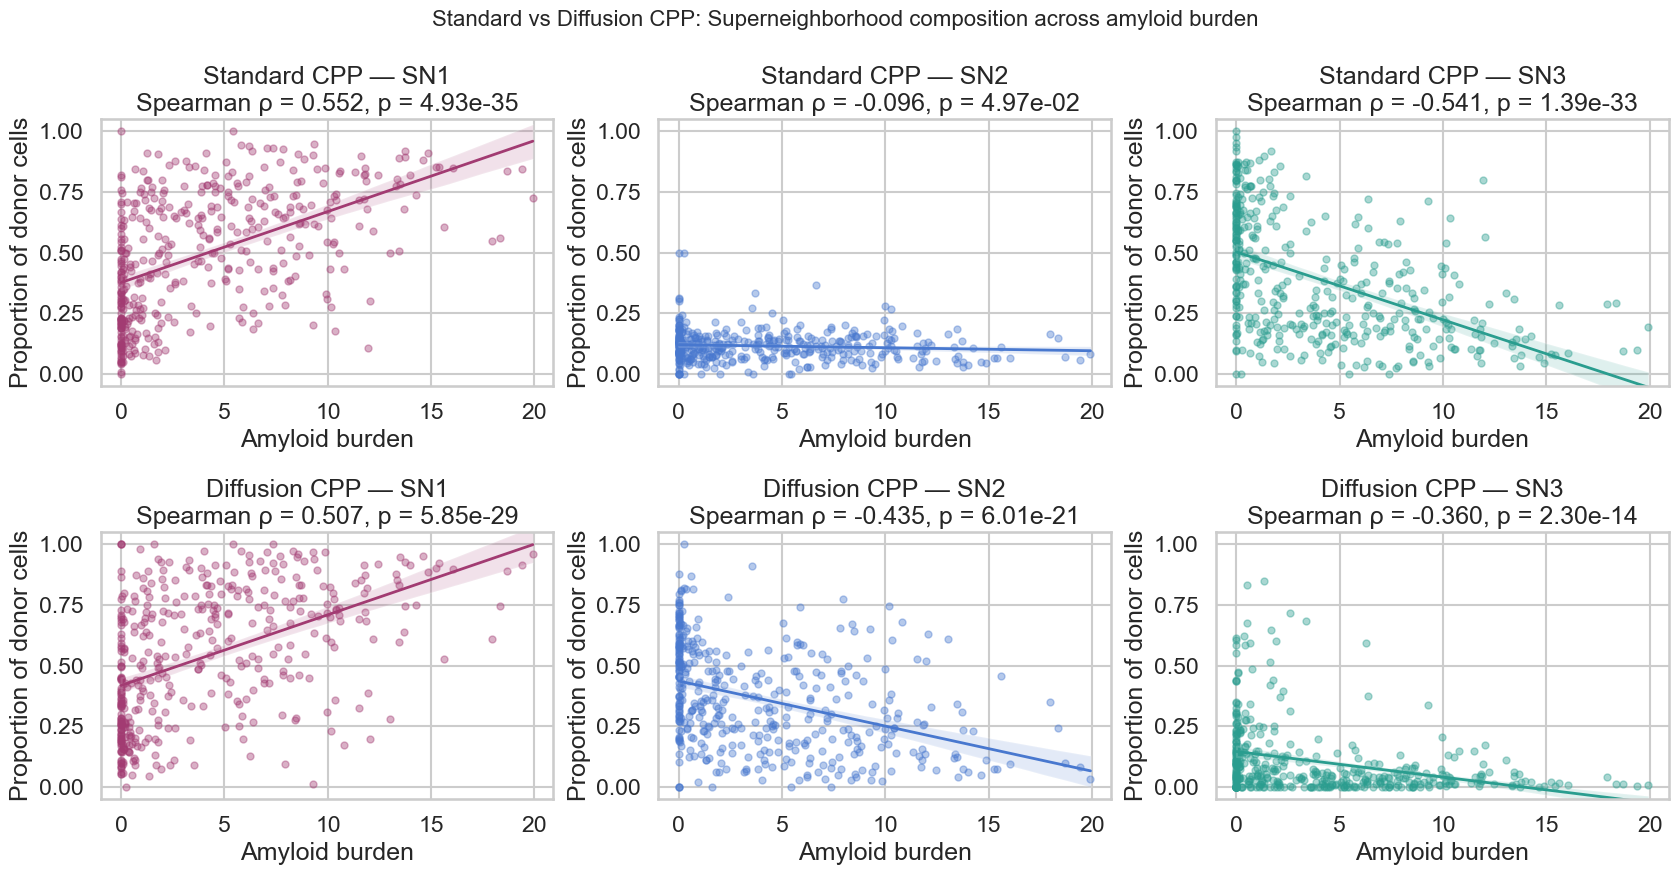

In [64]:
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sn_compare = compare.dropna(subset=["amyloid", "SN", "standard_SN"]).copy()

fig, axes = plt.subplots(2, 3, figsize=(17, 9))

colors = ["#A23B72", "#4878CF", "#2A9D8F"]

for row, (method, column) in enumerate([
    ("Standard CPP", "standard_SN"),
    ("Diffusion CPP", "SN")
]):
    donor_props = pd.crosstab(
        sn_compare["projid"],
        sn_compare[column],
        normalize="index"
    ).reindex(columns=["SN1", "SN2", "SN3"], fill_value=0)

    donor_props["amyloid"] = sn_compare.groupby("projid")["amyloid"].first()

    for j, sn in enumerate(["SN1", "SN2", "SN3"]):
        ax = axes[row, j]

        data = donor_props[["amyloid", sn]].dropna()
        rho, p = spearmanr(data["amyloid"], data[sn])

        sns.regplot(
            data=data,
            x="amyloid",
            y=sn,
            ax=ax,
            color=colors[j],
            scatter_kws={"alpha": 0.4, "s": 25},
            line_kws={"linewidth": 2}
        )

        ax.set_title(f"{method} — {sn}\nSpearman ρ = {rho:.3f}, p = {p:.2e}")
        ax.set_xlabel("Amyloid burden")
        ax.set_ylabel("Proportion of donor cells")
        ax.set_ylim(-0.05, 1.05)

plt.suptitle("Standard vs Diffusion CPP: Superneighborhood composition across amyloid burden", fontsize=16)
plt.tight_layout()
plt.show()

In [65]:
import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist

print("Available embeddings:", list(ad_diff.obsm.keys()))

X = np.asarray(ad_diff.obsm["X_diffusion"])
labels = ad_diff.obs["SN"].astype("string")

valid = labels.isin(["SN1", "SN2", "SN3"]).to_numpy()
X_valid = X[valid]
sn_valid = labels[valid].to_numpy()

centroids = np.vstack([
    X_valid[sn_valid == sn].mean(axis=0)
    for sn in ["SN1", "SN2", "SN3"]
])

distances = pd.DataFrame(
    cdist(centroids, centroids),
    index=["SN1", "SN2", "SN3"],
    columns=["SN1", "SN2", "SN3"]
)

display(distances)

Available embeddings: ['X_diffusion', 'X_pca']


,SN1,SN2,SN3
SN1,0.000000,0.002229,0.003025
SN2,0.002229,0.000000,0.002476
SN3,0.003025,0.002476,0.000000


# APOE trajectory analysis

In [66]:

import pandas as pd
import numpy as np

df = ad_diff.obs[["projid", "apoe_genotype", "SN", "amyloid"]].copy()
df = df[df["SN"].isin(["SN1", "SN2", "SN3"])]

df["apoe_genotype"] = (
    df["apoe_genotype"].astype("string")
    .str.replace(r"\.0$", "", regex=True)
    .str.strip()
)

donor_genotypes = df.groupby("projid")["apoe_genotype"].first()

print("Donors per APOE genotype:")
print(donor_genotypes.value_counts(dropna=False).sort_index())

print("\nCells per APOE genotype:")
print(df["apoe_genotype"].value_counts(dropna=False).sort_index())


Donors per APOE genotype:
apoe_genotype
22        3
23       55
24       10
33      249
34       97
44        8
<NA>      2
Name: count, dtype: Int64

Cells per APOE genotype:
apoe_genotype
22        254
23       6846
24       1569
33      43622
34      17662
44       1209
<NA>       43
Name: count, dtype: Int64


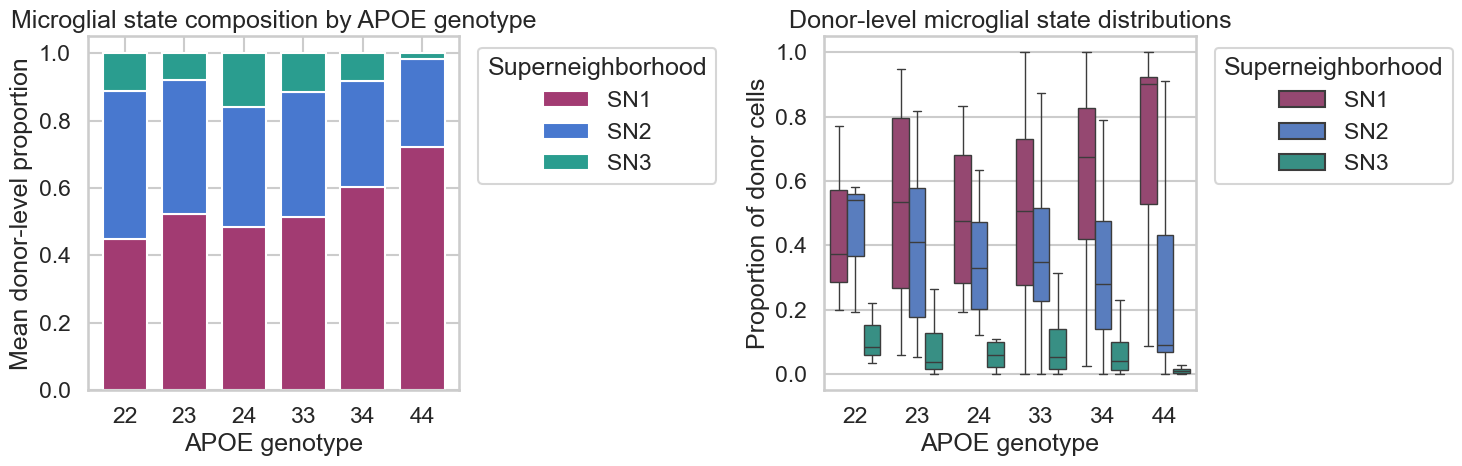

,SN1,SN2,SN3
apoe_genotype,,,
22,0.448432,0.438492,0.113076
23,0.522516,0.396918,0.080566
24,0.484430,0.355203,0.160366
33,0.512392,0.371589,0.116019
34,0.601583,0.314905,0.083512
44,0.722435,0.260806,0.016760


In [67]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

counts = pd.crosstab(df["projid"], df["SN"])
counts = counts.reindex(columns=["SN1", "SN2", "SN3"], fill_value=0)

proportions = counts.div(counts.sum(axis=1), axis=0)

donor_apoe = df.groupby("projid")["apoe_genotype"].first()

donor_apoe_df = proportions.join(donor_apoe)
donor_apoe_df = donor_apoe_df[donor_apoe_df["apoe_genotype"].isin(["22", "23", "24", "33", "34", "44"])]

order = ["22", "23", "24", "33", "34", "44"]
colors = ["#A23B72", "#4878CF", "#2A9D8F"]

means = donor_apoe_df.groupby("apoe_genotype")[["SN1", "SN2", "SN3"]].mean().reindex(order)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

means.plot(kind="bar", stacked=True, color=colors, ax=axes[0], width=0.75)
axes[0].set_title("Microglial state composition by APOE genotype")
axes[0].set_xlabel("APOE genotype")
axes[0].set_ylabel("Mean donor-level proportion")
axes[0].legend(title="Superneighborhood", bbox_to_anchor=(1.02, 1), loc="upper left")
axes[0].tick_params(axis="x", rotation=0)

plot_df = donor_apoe_df.reset_index().melt(
    id_vars=["projid", "apoe_genotype"],
    value_vars=["SN1", "SN2", "SN3"],
    var_name="SN",
    value_name="Proportion"
)

sns.boxplot(data=plot_df, x="apoe_genotype", y="Proportion", hue="SN", order=order, palette=colors, showfliers=False, ax=axes[1])
axes[1].set_title("Donor-level microglial state distributions")
axes[1].set_xlabel("APOE genotype")
axes[1].set_ylabel("Proportion of donor cells")
axes[1].legend(title="Superneighborhood", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

display(means)


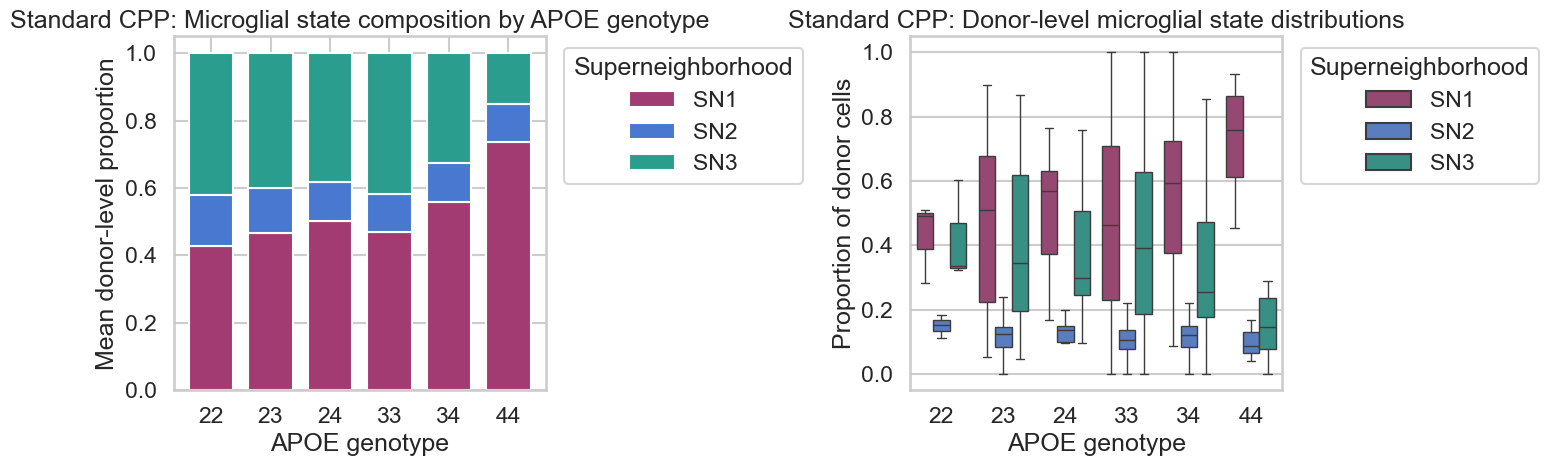

Standard CPP donors: 422


,SN1,SN2,SN3
apoe_genotype,,,
22,0.428605,0.150556,0.420838
23,0.466615,0.131811,0.401574
24,0.502857,0.114255,0.382888
33,0.470104,0.110947,0.418949
34,0.557937,0.117522,0.324541
44,0.737321,0.112488,0.150191


In [68]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

std_labels = std[["cell", "SN"]].drop_duplicates("cell").set_index("cell")

std_df = ad_diff.obs[["projid", "apoe_genotype"]].copy()
std_df["SN"] = std_df.index.map(std_labels["SN"])

std_df = std_df[std_df["SN"].isin(["SN1", "SN2", "SN3"])].copy()
std_df["apoe_genotype"] = std_df["apoe_genotype"].astype("string").str.replace(r"\.0$", "", regex=True).str.strip()

counts_std = pd.crosstab(std_df["projid"], std_df["SN"])
counts_std = counts_std.reindex(columns=["SN1", "SN2", "SN3"], fill_value=0)

proportions_std = counts_std.div(counts_std.sum(axis=1), axis=0)
donor_apoe_std = std_df.groupby("projid")["apoe_genotype"].first()

donor_apoe_df_std = proportions_std.join(donor_apoe_std)
order = ["22", "23", "24", "33", "34", "44"]
donor_apoe_df_std = donor_apoe_df_std[donor_apoe_df_std["apoe_genotype"].isin(order)]

colors = ["#A23B72", "#4878CF", "#2A9D8F"]
means_std = donor_apoe_df_std.groupby("apoe_genotype")[["SN1", "SN2", "SN3"]].mean().reindex(order)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

means_std.plot(kind="bar", stacked=True, color=colors, ax=axes[0], width=0.75)
axes[0].set_title("Standard CPP: Microglial state composition by APOE genotype")
axes[0].set_xlabel("APOE genotype")
axes[0].set_ylabel("Mean donor-level proportion")
axes[0].legend(title="Superneighborhood", bbox_to_anchor=(1.02, 1), loc="upper left")
axes[0].tick_params(axis="x", rotation=0)

plot_std = donor_apoe_df_std.reset_index().melt(
    id_vars=["projid", "apoe_genotype"],
    value_vars=["SN1", "SN2", "SN3"],
    var_name="SN",
    value_name="Proportion"
)

sns.boxplot(data=plot_std, x="apoe_genotype", y="Proportion", hue="SN", order=order, palette=colors, showfliers=False, ax=axes[1])
axes[1].set_title("Standard CPP: Donor-level microglial state distributions")
axes[1].set_xlabel("APOE genotype")
axes[1].set_ylabel("Proportion of donor cells")
axes[1].legend(title="Superneighborhood", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

print("Standard CPP donors:", len(donor_apoe_df_std))
display(means_std)


In [22]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, balanced_accuracy_score, average_precision_score

std_labels = std.drop_duplicates("cell").set_index("cell")["SN"]
std_score_map = std_scores.drop_duplicates("cell").set_index("cell")["standard_cpp_score"]

cells = ad_diff.obs[["projid", "SN", "AD_score_diffusion_CPP", "apoe_genotype"]].copy()
cells["SN_std"] = cells.index.map(std_labels)
cells["score_std"] = cells.index.map(std_score_map)

def donor_features(data, sn_col, score_col, prefix):
    valid = data[data[sn_col].isin(["SN1", "SN2", "SN3"])].copy()
    proportions = pd.crosstab(valid["projid"], valid[sn_col], normalize="index")
    proportions = proportions.reindex(columns=["SN1", "SN2", "SN3"], fill_value=0)
    proportions = proportions.rename(columns=lambda x: f"{prefix}_{x}")
    scores = valid.groupby("projid")[score_col].mean().rename(f"{prefix}_score")
    return proportions.join(scores)

features_std = donor_features(cells, "SN_std", "score_std", "std")
features_diff = donor_features(cells, "SN", "AD_score_diffusion_CPP", "diff")

features = features_std.join(features_diff, how="inner")
features = features.dropna()

std_cols = ["std_SN1", "std_SN2", "std_score"]
diff_cols = ["diff_SN1", "diff_SN2", "diff_score"]

models = {
    "Standard CPP": std_cols,
    "Diffusion CPP": diff_cols,
    "Combined": std_cols + diff_cols
}

print("Donors with complete features:", len(features))
display(features.head())


Donors with complete features: 424


,std_SN1,std_SN2,std_SN3,std_score,diff_SN1,diff_SN2,diff_SN3,diff_score
projid,,,,,,,,
10100574,0.291391,0.145695,0.562914,-0.139779,0.324324,0.574324,0.101351,-0.108676
10100862,0.143662,0.104225,0.752113,-0.287182,0.200565,0.548023,0.251412,-0.244500
10101291,0.666667,0.142857,0.190476,0.096751,0.571429,0.428571,0.000000,0.084147
10101327,0.466667,0.333333,0.200000,0.082070,0.733333,0.266667,0.000000,0.111317
10101589,0.747475,0.131313,0.121212,0.237862,0.683673,0.306122,0.010204,0.234360


In [70]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

std_labels = std.drop_duplicates("cell").set_index("cell")["SN"]

df = ad_diff.obs[["projid", "amyloid", "apoe_genotype", "SN"]].copy()
df["SN_standard"] = df.index.map(std_labels)
df = df.rename(columns={"SN": "SN_diffusion"})

df["apoe_genotype"] = df["apoe_genotype"].astype("string").str.replace(r"\.0$", "", regex=True).str.strip()
df["amyloid"] = pd.to_numeric(df["amyloid"], errors="coerce")

donor_info = df.groupby("projid")[["amyloid", "apoe_genotype"]].first()

def get_proportions(data, column, prefix):
    valid = data[data[column].isin(["SN1", "SN2", "SN3"])]
    proportions = pd.crosstab(valid["projid"], valid[column], normalize="index")
    proportions = proportions.reindex(columns=["SN1", "SN2", "SN3"], fill_value=0)
    return proportions.add_prefix(prefix + "_")

diff_props = get_proportions(df, "SN_diffusion", "Diffusion")
std_props = get_proportions(df, "SN_standard", "Standard")

donors = donor_info.join(diff_props, how="inner").join(std_props, how="inner").dropna()

apoe44 = donors[donors["apoe_genotype"] == "44"].copy()

print("APOE 44 donors:", len(apoe44))
display(apoe44.sort_values("amyloid"))


APOE 44 donors: 8


,amyloid,apoe_genotype,Diffusion_SN1,Diffusion_SN2,Diffusion_SN3,Standard_SN1,Standard_SN2,Standard_SN3
projid,,,,,,,,
10248033,3.538750,44,0.088235,0.911765,0.000000,0.454545,0.272727,0.272727
11157783,3.711500,44,0.495495,0.432432,0.072072,0.612613,0.099099,0.288288
84642424,6.736250,44,0.929730,0.059459,0.010811,0.685864,0.120419,0.193717
21159840,7.367500,44,1.000000,0.000000,0.000000,0.931818,0.068182,0.000000
11630705,7.840833,44,0.920000,0.072000,0.008000,0.926829,0.040650,0.032520
20963866,8.903438,44,0.541667,0.430556,0.027778,0.611111,0.166667,0.222222
26631069,18.690313,44,0.889503,0.099448,0.011050,0.833333,0.075269,0.091398
76733461,19.395625,44,0.914847,0.080786,0.004367,0.842451,0.056893,0.100656


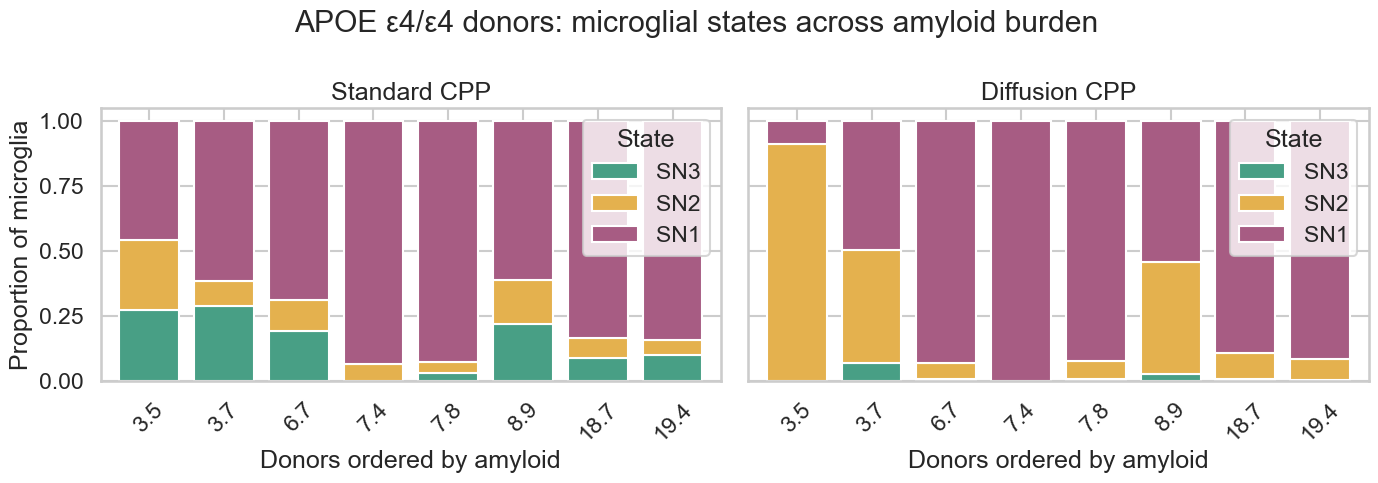

In [71]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

apoe44_plot = apoe44.sort_values("amyloid")

for ax, method in zip(axes, ["Standard", "Diffusion"]):
    values = apoe44_plot[[f"{method}_SN3", f"{method}_SN2", f"{method}_SN1"]]
    values.columns = ["SN3", "SN2", "SN1"]

    values.plot(
        kind="bar",
        stacked=True,
        ax=ax,
        color=["#489F85", "#E4B14E", "#A75C83"],
        width=0.8
    )

    ax.set_title(f"{method} CPP")
    ax.set_xlabel("Donors ordered by amyloid")
    ax.set_ylabel("Proportion of microglia")
    ax.set_xticklabels([f"{x:.1f}" for x in apoe44_plot["amyloid"]], rotation=45)
    ax.legend(title="State")

plt.suptitle("APOE ε4/ε4 donors: microglial states across amyloid burden")
plt.tight_layout()
plt.show()


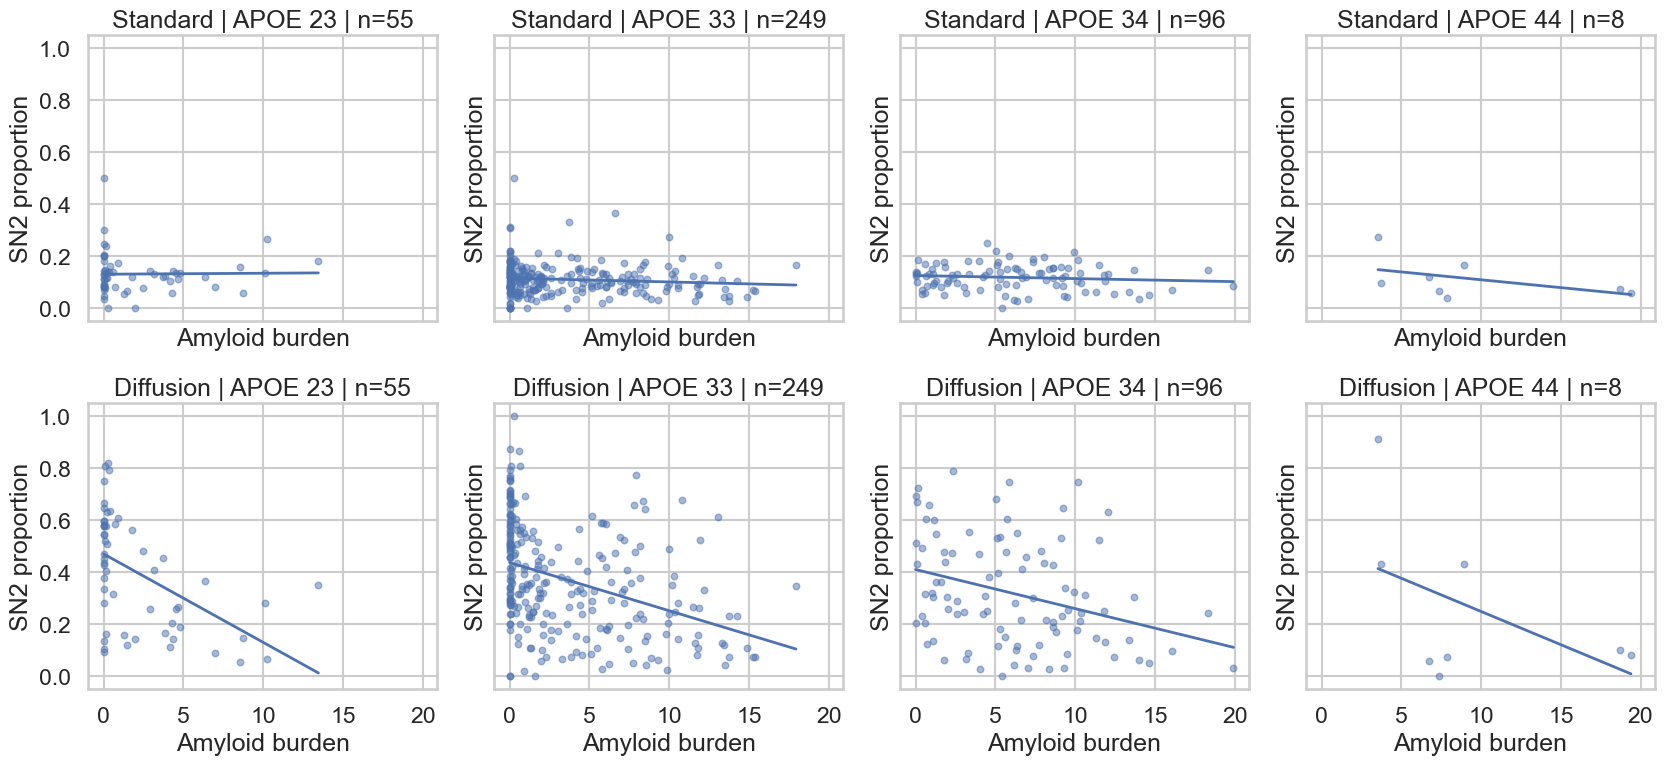

In [72]:

genotypes = ["23", "33", "34", "44"]

fig, axes = plt.subplots(2, 4, figsize=(17, 8), sharex=True, sharey=True)

for j, genotype in enumerate(genotypes):
    sub = donors[donors["apoe_genotype"] == genotype]

    for i, method in enumerate(["Standard", "Diffusion"]):
        ax = axes[i, j]

        sns.regplot(
            data=sub,
            x="amyloid",
            y=f"{method}_SN2",
            ax=ax,
            scatter_kws={"alpha": 0.5, "s": 22},
            line_kws={"linewidth": 2},
            ci=None
        )

        ax.set_title(f"{method} | APOE {genotype} | n={len(sub)}")
        ax.set_xlabel("Amyloid burden")
        ax.set_ylabel("SN2 proportion")

plt.tight_layout()
plt.show()


In [75]:
apoe44 = donors[donors["apoe_genotype"] == "44"].copy()

for method in ["Diffusion", "Standard"]:
    columns = [f"{method}_SN1", f"{method}_SN2", f"{method}_SN3"]
    apoe44[f"{method}_dominant"] = (
        apoe44[columns].idxmax(axis=1).str.replace(f"{method}_", "", regex=False)
    )

display(apoe44[[
    "amyloid",
    "Diffusion_dominant", "Standard_dominant",
    "Diffusion_SN1", "Diffusion_SN2", "Diffusion_SN3",
    "Standard_SN1", "Standard_SN2", "Standard_SN3"
]].sort_values("amyloid"))

,amyloid,Diffusion_dominant,Standard_dominant,Diffusion_SN1,Diffusion_SN2,Diffusion_SN3,Standard_SN1,Standard_SN2,Standard_SN3
projid,,,,,,,,,
10248033,3.538750,SN2,SN1,0.088235,0.911765,0.000000,0.454545,0.272727,0.272727
11157783,3.711500,SN1,SN1,0.495495,0.432432,0.072072,0.612613,0.099099,0.288288
84642424,6.736250,SN1,SN1,0.929730,0.059459,0.010811,0.685864,0.120419,0.193717
21159840,7.367500,SN1,SN1,1.000000,0.000000,0.000000,0.931818,0.068182,0.000000
11630705,7.840833,SN1,SN1,0.920000,0.072000,0.008000,0.926829,0.040650,0.032520
20963866,8.903438,SN1,SN1,0.541667,0.430556,0.027778,0.611111,0.166667,0.222222
26631069,18.690313,SN1,SN1,0.889503,0.099448,0.011050,0.833333,0.075269,0.091398
76733461,19.395625,SN1,SN1,0.914847,0.080786,0.004367,0.842451,0.056893,0.100656


In [76]:
results = []

for method in ["Diffusion", "Standard"]:
    for sn in ["SN1", "SN2", "SN3"]:
        values = apoe44.loc[apoe44[f"{method}_dominant"] == sn, "amyloid"]

        results.append({
            "Method": method,
            "SN": sn,
            "Donors": len(values),
            "Mean amyloid": values.mean(),
            "Median amyloid": values.median()
        })

summary = pd.DataFrame(results)
display(summary.round(3))

,Method,SN,Donors,Mean amyloid,Median amyloid
0,Diffusion,SN1,7,10.378,7.841
1,Diffusion,SN2,1,3.539,3.539
2,Diffusion,SN3,0,NaN,NaN
3,Standard,SN1,8,9.523,7.604
4,Standard,SN2,0,NaN,NaN
5,Standard,SN3,0,NaN,NaN


In [77]:

all_results = []

for genotype in ["23", "33", "34", "44"]:
    subset = donors[donors["apoe_genotype"] == genotype].copy()

    for method in ["Diffusion", "Standard"]:
        columns = [f"{method}_SN1", f"{method}_SN2", f"{method}_SN3"]
        subset["dominant"] = subset[columns].idxmax(axis=1).str.replace(f"{method}_", "", regex=False)

        for sn in ["SN1", "SN2", "SN3"]:
            values = subset.loc[subset["dominant"] == sn, "amyloid"]

            all_results.append({
                "APOE": genotype,
                "Method": method,
                "SN": sn,
                "N donors": len(values),
                "Mean amyloid": values.mean(),
                "Median amyloid": values.median()
            })

comparison = pd.DataFrame(all_results)
display(comparison.round(3))


,APOE,Method,SN,N donors,Mean amyloid,Median amyloid
0,23,Diffusion,SN1,31,3.558,3.148
1,23,Diffusion,SN2,24,0.314,0.062
2,23,Diffusion,SN3,0,NaN,NaN
3,23,Standard,SN1,32,3.533,3.012
4,23,Standard,SN2,1,0.000,0.000
5,23,Standard,SN3,22,0.217,0.018
6,33,Diffusion,SN1,142,4.847,3.844
7,33,Diffusion,SN2,89,1.842,0.129
8,33,Diffusion,SN3,18,1.368,1.042
9,33,Standard,SN1,135,5.326,4.624


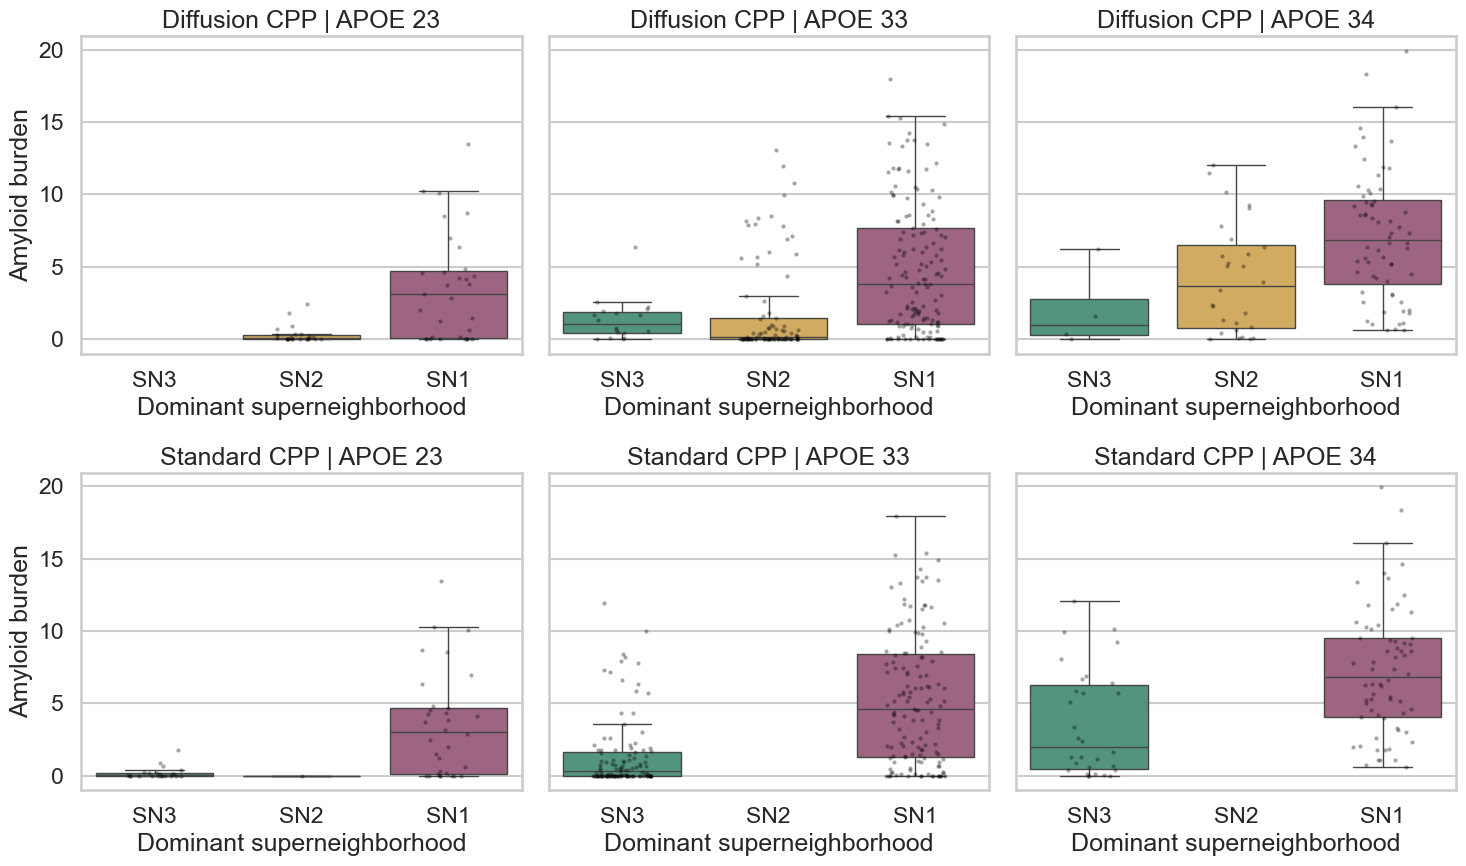

In [78]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

plot_data = []

for genotype in ["23", "33", "34", "44"]:
    sub = donors[donors["apoe_genotype"] == genotype].copy()

    for method in ["Diffusion", "Standard"]:
        columns = [f"{method}_SN1", f"{method}_SN2", f"{method}_SN3"]
        dominant = sub[columns].idxmax(axis=1).str.replace(f"{method}_", "", regex=False)

        temp = pd.DataFrame({
            "APOE": genotype,
            "Method": method,
            "SN": dominant,
            "Amyloid": sub["amyloid"]
        })

        plot_data.append(temp)

plot_df = pd.concat(plot_data, ignore_index=True)

fig, axes = plt.subplots(2, 3, figsize=(15, 9), sharey=True)
palette = {"SN3": "#489F85", "SN2": "#E4B14E", "SN1": "#A75C83"}

for i, method in enumerate(["Diffusion", "Standard"]):
    for j, genotype in enumerate(["23", "33", "34"]):
        ax = axes[i, j]
        sub = plot_df[(plot_df["Method"] == method) & (plot_df["APOE"] == genotype)]

        sns.boxplot(data=sub, x="SN", y="Amyloid", order=["SN3", "SN2", "SN1"], hue="SN", palette=palette, showfliers=False, ax=ax, legend=False)
        sns.stripplot(data=sub, x="SN", y="Amyloid", order=["SN3", "SN2", "SN1"], color="black", alpha=0.35, size=3, jitter=0.2, ax=ax)

        ax.set_title(f"{method} CPP | APOE {genotype}")
        ax.set_xlabel("Dominant superneighborhood")
        ax.set_ylabel("Amyloid burden")

plt.tight_layout()
plt.show()


In [79]:

import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

test_results = []

for genotype in ["23", "33", "34"]:
    sub = plot_df[
        (plot_df["Method"] == "Diffusion") &
        (plot_df["APOE"] == genotype)
    ].copy()

    for lower, higher in [("SN3", "SN2"), ("SN2", "SN1")]:
        x = sub.loc[sub["SN"] == lower, "Amyloid"].dropna()
        y = sub.loc[sub["SN"] == higher, "Amyloid"].dropna()

        if len(x) >= 2 and len(y) >= 2:
            stat, p = mannwhitneyu(y, x, alternative="greater")
        else:
            stat, p = np.nan, np.nan

        test_results.append({
            "APOE": genotype,
            "Comparison": f"{higher} > {lower}",
            "n lower": len(x),
            "n higher": len(y),
            "Median lower": x.median(),
            "Median higher": y.median(),
            "p": p
        })

ordering_tests = pd.DataFrame(test_results)

mask = ordering_tests["p"].notna()
ordering_tests["p_holm"] = np.nan
ordering_tests.loc[mask, "p_holm"] = multipletests(
    ordering_tests.loc[mask, "p"], method="holm"
)[1]

display(ordering_tests.round(5))


,APOE,Comparison,n lower,n higher,Median lower,Median higher,p,p_holm
0,23,SN2 > SN3,0,24,NaN,0.06188,NaN,NaN
1,23,SN1 > SN2,24,31,0.06188,3.14750,0.00035,0.00141
2,33,SN2 > SN3,18,89,1.04167,0.12937,0.97286,0.97286
3,33,SN1 > SN2,89,142,0.12937,3.84438,0.00000,0.00000
4,34,SN2 > SN3,4,28,0.99917,3.66078,0.13317,0.26634
5,34,SN1 > SN2,28,64,3.66078,6.85119,0.00143,0.00429


In [80]:

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

cells = ad_diff.obs[["projid", "amyloid", "apoe_genotype", "SN"]].copy()

cells = cells.rename(columns={"SN": "SN_diffusion"})
cells["SN_standard"] = cells.index.map(std.drop_duplicates("cell").set_index("cell")["SN"])
cells["amyloid"] = pd.to_numeric(cells["amyloid"], errors="coerce")
cells["apoe_genotype"] = cells["apoe_genotype"].astype("string").str.replace(r"\.0$", "", regex=True).str.strip()

cells = cells.dropna(subset=["projid", "amyloid", "apoe_genotype"])

print("Cells:", len(cells))
print("Donors:", cells["projid"].nunique())


Cells: 72939
Donors: 421


In [81]:

results = []

for genotype in ["23", "33", "34", "44"]:
    sub = cells[cells["apoe_genotype"] == genotype]

    for method in ["diffusion", "standard"]:
        for sn in ["SN1", "SN2", "SN3"]:
            group = sub[sub[f"SN_{method}"] == sn]

            results.append({
                "APOE": genotype,
                "Method": method,
                "SN": sn,
                "Cells": len(group),
                "Donors": group["projid"].nunique(),
                "Mean amyloid": group["amyloid"].mean(),
                "Median amyloid": group["amyloid"].median()
            })

cell_summary = pd.DataFrame(results)
display(cell_summary.round(4))


,APOE,Method,SN,Cells,Donors,Mean amyloid,Median amyloid
0,23,diffusion,SN1,3548,55,3.6543,2.8769
1,23,diffusion,SN2,2689,55,1.9102,0.1919
2,23,diffusion,SN3,609,45,1.3301,0.1800
3,23,standard,SN1,3297,55,3.5710,3.1475
4,23,standard,SN2,867,53,2.7435,0.6938
5,23,standard,SN3,2735,55,1.7799,0.1919
6,33,diffusion,SN1,21618,248,4.7725,3.8462
7,33,diffusion,SN2,15282,246,2.4642,0.6719
8,33,diffusion,SN3,6722,211,1.3062,0.5081
9,33,standard,SN1,19892,248,4.9440,4.2428


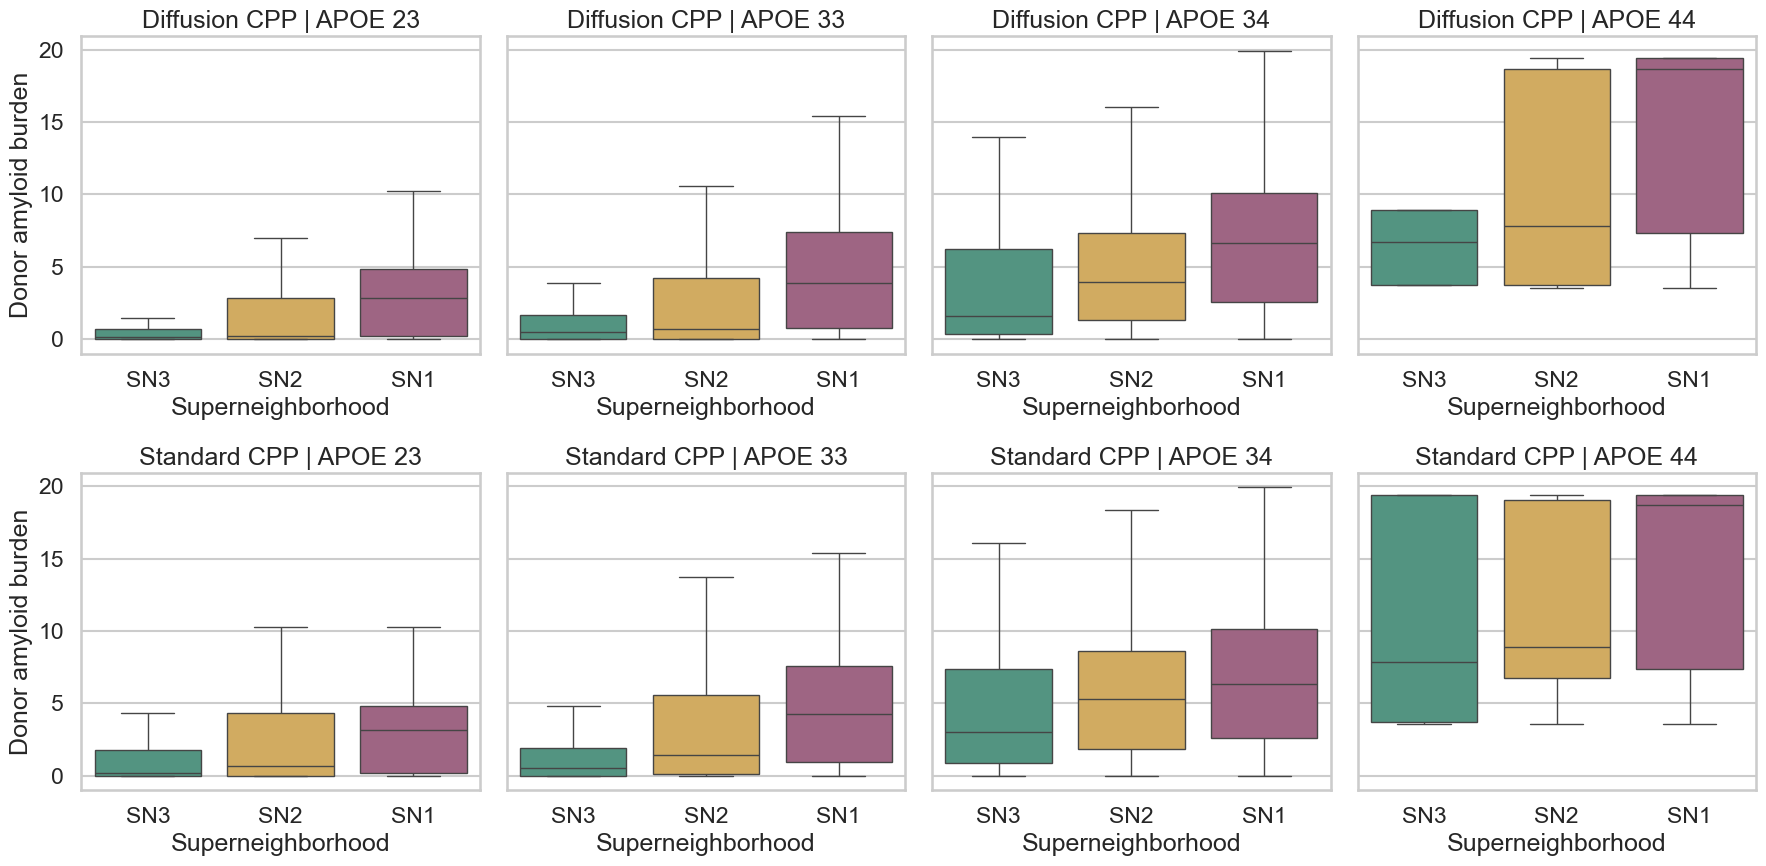

In [82]:

fig, axes = plt.subplots(2, 4, figsize=(18, 9), sharey=True)

palette = {"SN3": "#489F85", "SN2": "#E4B14E", "SN1": "#A75C83"}

for i, method in enumerate(["diffusion", "standard"]):
    for j, genotype in enumerate(["23", "33", "34", "44"]):
        sub = cells[cells["apoe_genotype"] == genotype]

        sns.boxplot(
            data=sub,
            x=f"SN_{method}",
            y="amyloid",
            order=["SN3", "SN2", "SN1"],
            hue=f"SN_{method}",
            palette=palette,
            showfliers=False,
            ax=axes[i, j],
            legend=False
        )

        axes[i, j].set_title(f"{method.capitalize()} CPP | APOE {genotype}")
        axes[i, j].set_xlabel("Superneighborhood")
        axes[i, j].set_ylabel("Donor amyloid burden")

plt.tight_layout()
plt.show()


In [83]:

import statsmodels.formula.api as smf
from scipy.stats import norm
from statsmodels.stats.multitest import multipletests

test_results = []

for genotype in ["33", "34"]:
    for method in ["diffusion", "standard"]:
        sub = cells[
            (cells["apoe_genotype"] == genotype) &
            (cells[f"SN_{method}"].isin(["SN1", "SN2", "SN3"])) &
            (cells["amyloid"] >= 0)
        ].copy()

        sub["SN_test"] = pd.Categorical(
            sub[f"SN_{method}"], categories=["SN3", "SN2", "SN1"]
        )

        if sub["SN_test"].nunique() < 3:
            continue

        sub["log_amyloid"] = np.log1p(sub["amyloid"])

        model = smf.ols(
            "log_amyloid ~ C(SN_test)",
            data=sub
        ).fit(cov_type="cluster", cov_kwds={"groups": sub["projid"]})

        names = model.params.index.tolist()

        for label, positive, negative in [
            ("SN2 > SN3", "C(SN_test)[T.SN2]", None),
            ("SN1 > SN2", "C(SN_test)[T.SN1]", "C(SN_test)[T.SN2]")
        ]:
            contrast = np.zeros(len(names))
            contrast[names.index(positive)] = 1

            if negative is not None:
                contrast[names.index(negative)] = -1

            test = model.t_test(contrast)
            estimate = float(np.asarray(test.effect).item())
            z = float(np.asarray(test.tvalue).item())

            test_results.append({
                "APOE": genotype,
                "Method": method,
                "Comparison": label,
                "Difference": estimate,
                "One-sided p": norm.sf(z)
            })

cell_tests = pd.DataFrame(test_results)
cell_tests["p_holm"] = multipletests(cell_tests["One-sided p"], method="holm")[1]

display(cell_tests.round(6))


,APOE,Method,Comparison,Difference,One-sided p,p_holm
0,33,diffusion,SN2 > SN3,0.257298,0.000002,0.000012
1,33,diffusion,SN1 > SN2,0.556488,0.000000,0.000000
2,33,standard,SN2 > SN3,0.336067,0.000000,0.000000
3,33,standard,SN1 > SN2,0.386846,0.000000,0.000000
4,34,diffusion,SN2 > SN3,0.402562,0.009787,0.009787
5,34,diffusion,SN1 > SN2,0.417314,0.000003,0.000013
6,34,standard,SN2 > SN3,0.258998,0.000046,0.000138
7,34,standard,SN1 > SN2,0.227569,0.000174,0.000348


In [84]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

boot_cells = cells[
    cells["apoe_genotype"].isin(["33", "34"]) &
    cells["amyloid"].notna() &
    (cells["amyloid"] >= 0)
].copy()

boot_cells["log_amyloid"] = np.log1p(boot_cells["amyloid"])

print("Cells:", len(boot_cells))
print("Donors:", boot_cells["projid"].nunique())

display(boot_cells[["projid", "apoe_genotype", "log_amyloid", "SN_diffusion", "SN_standard"]].head())


Cells: 62783
Donors: 345


,projid,apoe_genotype,log_amyloid,SN_diffusion,SN_standard
AACTTTCAGGATGGTC-1-0,11409232,33,0.0,SN2,SN3
ACGGGCTCAATCAGAA-1-0,11409232,33,0.0,SN1,SN3
AGCGGTCAGATGTTAG-1-0,11409232,33,0.0,SN2,SN3
AGTGAGGGTGGTAACG-1-0,11409232,33,0.0,SN2,SN1
ATTACTCAGGAGTAGA-1-0,11409232,33,0.0,SN2,SN3


In [85]:

records = []

for method in ["diffusion", "standard"]:
    temp = boot_cells[
        boot_cells[f"SN_{method}"].isin(["SN1", "SN2", "SN3"])
    ].copy()

    grouped = temp.groupby(
        ["apoe_genotype", "projid", f"SN_{method}"],
        observed=True
    ).agg(
        n_cells=("log_amyloid", "size"),
        sum_amyloid=("log_amyloid", "sum")
    ).reset_index()

    grouped = grouped.rename(columns={f"SN_{method}": "SN"})
    grouped["Method"] = method
    records.append(grouped)

donor_stats = pd.concat(records, ignore_index=True)

display(donor_stats.head())


,apoe_genotype,projid,SN,n_cells,sum_amyloid,Method
0,33,10100574,SN1,48,28.063525,diffusion
1,33,10100574,SN2,85,49.695826,diffusion
2,33,10100574,SN3,15,8.769852,diffusion
3,33,10101327,SN1,11,17.025138,diffusion
4,33,10101327,SN2,4,6.190959,diffusion


In [86]:

rng = np.random.default_rng(42)
B = 3000

bootstrap_rows = []
observed_rows = []

for genotype in ["33", "34"]:
    sub = donor_stats[donor_stats["apoe_genotype"] == genotype].copy()
    donor_ids = sub["projid"].unique()

    index = pd.MultiIndex.from_product(
        [donor_ids, ["diffusion", "standard"], ["SN1", "SN2", "SN3"]],
        names=["projid", "Method", "SN"]
    )

    counts = sub.set_index(["projid", "Method", "SN"])["n_cells"].reindex(index, fill_value=0)
    sums = sub.set_index(["projid", "Method", "SN"])["sum_amyloid"].reindex(index, fill_value=0)

    counts = counts.to_numpy().reshape(len(donor_ids), 2, 3)
    sums = sums.to_numpy().reshape(len(donor_ids), 2, 3)

    def calculate_contrasts(weights):
        total_n = np.einsum("d,dms->ms", weights, counts)
        total_sum = np.einsum("d,dms->ms", weights, sums)

        if np.any(total_n == 0):
            return None

        means = total_sum / total_n

        contrasts = np.column_stack([
            means[:, 1] - means[:, 2],
            means[:, 0] - means[:, 1]
        ])

        return contrasts

    observed = calculate_contrasts(np.ones(len(donor_ids)))

    if observed is None:
        raise ValueError(f"Missing SN in genotype {genotype}")

    for k, label in enumerate(["SN2 − SN3", "SN1 − SN2"]):
        observed_rows.append({
            "APOE": genotype,
            "Contrast": label,
            "Diffusion": observed[0, k],
            "Standard": observed[1, k],
            "Difference": observed[0, k] - observed[1, k]
        })

    for b in range(B):
        sampled = rng.integers(0, len(donor_ids), len(donor_ids))
        weights = np.bincount(sampled, minlength=len(donor_ids))
        estimates = calculate_contrasts(weights)

        if estimates is None:
            continue

        for k, label in enumerate(["SN2 − SN3", "SN1 − SN2"]):
            bootstrap_rows.append({
                "APOE": genotype,
                "Iteration": b,
                "Contrast": label,
                "Diffusion": estimates[0, k],
                "Standard": estimates[1, k],
                "Difference": estimates[0, k] - estimates[1, k]
            })

bootstrap_df = pd.DataFrame(bootstrap_rows)
observed_df = pd.DataFrame(observed_rows)

print("Bootstrap iterations completed:", bootstrap_df["Iteration"].nunique())
display(observed_df.round(4))


Bootstrap iterations completed: 3000


,APOE,Contrast,Diffusion,Standard,Difference
0,33,SN2 − SN3,0.2573,0.3361,-0.0788
1,33,SN1 − SN2,0.5565,0.3868,0.1696
2,34,SN2 − SN3,0.4026,0.2590,0.1436
3,34,SN1 − SN2,0.4173,0.2276,0.1897


In [87]:

summary_rows = []

for (genotype, contrast), group in bootstrap_df.groupby(["APOE", "Contrast"]):
    observed = observed_df[
        (observed_df["APOE"] == genotype) &
        (observed_df["Contrast"] == contrast)
    ].iloc[0]

    differences = group["Difference"].to_numpy()

    ci_low, ci_high = np.percentile(differences, [2.5, 97.5])

    summary_rows.append({
        "APOE": genotype,
        "Contrast": contrast,
        "Diffusion": observed["Diffusion"],
        "Standard": observed["Standard"],
        "Diffusion − Standard": observed["Difference"],
        "CI lower": ci_low,
        "CI upper": ci_high,
        "CI excludes zero": ci_low > 0 or ci_high < 0,
        "Valid bootstraps": len(differences)
    })

bootstrap_summary = pd.DataFrame(summary_rows)

display(bootstrap_summary.round(5))


,APOE,Contrast,Diffusion,Standard,Diffusion − Standard,CI lower,CI upper,CI excludes zero,Valid bootstraps
0,33,SN1 − SN2,0.55649,0.38685,0.16964,0.09286,0.24492,True,3000
1,33,SN2 − SN3,0.25730,0.33607,-0.07877,-0.17413,0.01735,False,3000
2,34,SN1 − SN2,0.41731,0.22757,0.18974,0.07215,0.29734,True,3000
3,34,SN2 − SN3,0.40256,0.25900,0.14356,-0.12879,0.40212,False,3000


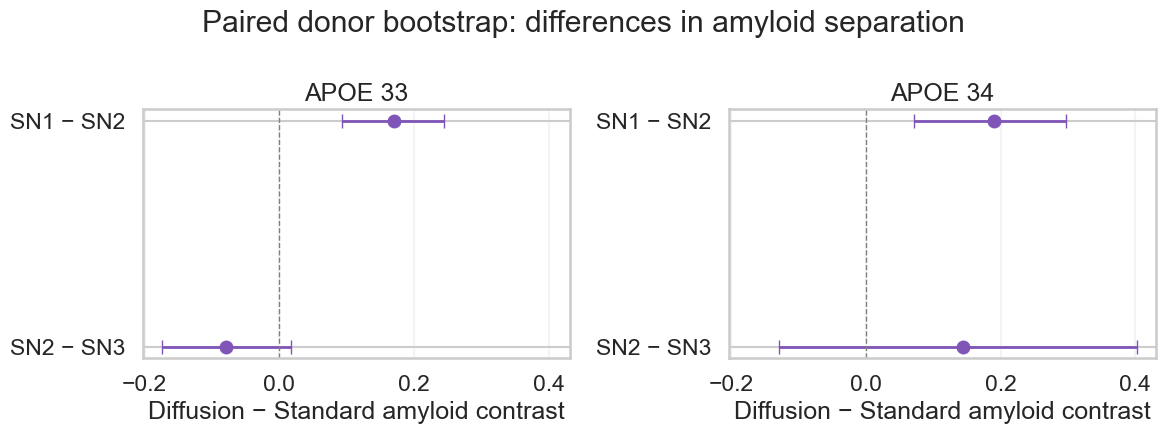

In [88]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)

for ax, genotype in zip(axes, ["33", "34"]):
    sub = bootstrap_summary[bootstrap_summary["APOE"] == genotype].copy()
    sub = sub.set_index("Contrast").loc[["SN2 − SN3", "SN1 − SN2"]].reset_index()

    y = np.arange(len(sub))

    ax.errorbar(
        sub["Diffusion − Standard"],
        y,
        xerr=[
            sub["Diffusion − Standard"] - sub["CI lower"],
            sub["CI upper"] - sub["Diffusion − Standard"]
        ],
        fmt="o",
        color="#8055B8",
        markersize=9,
        capsize=5,
        linewidth=2
    )

    ax.axvline(0, color="gray", linestyle="--", linewidth=1)
    ax.set_yticks(y)
    ax.set_yticklabels(sub["Contrast"])
    ax.set_title(f"APOE {genotype}")
    ax.set_xlabel("Diffusion − Standard amyloid contrast")
    ax.grid(axis="x", alpha=0.2)

plt.suptitle("Paired donor bootstrap: differences in amyloid separation")
plt.tight_layout()
plt.show()
